# Best baseline: seasonal RTO forecast with momentum correction

Цель: предсказать `РТО` каждого магазина за март 2025.

Выбранная формула:

`forecast = February RTO * Mar/Feb seasonal factor * conservative momentum correction`

Она сохранила интерпретируемость baseline и на локальной проверке марта 2024 оказалась лучше простого сезонного коэффициента и Random Forest baseline.

In [1]:
import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path("analysis/.mplconfig")))
os.environ.setdefault("XDG_CACHE_HOME", str(Path("analysis/.cache")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "train_2.csv").exists():
    ROOT = ROOT.parent

DATA_PATH = ROOT / "train_2.csv"
SUBMISSION_PATH = ROOT / "submissions" / "test.csv"

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


## 1. Load data and verify time coverage

Одна строка — один магазин в одном месяце. Прогнозируем следующий месяц после последнего доступного периода.

In [2]:
df = pd.read_csv(DATA_PATH)
df["period"] = pd.to_datetime(
    df["Год"].astype(str) + "-" + df["Месяц"].astype(str).str.zfill(2) + "-01"
)
df["period_label"] = df["period"].dt.strftime("%Y-%m")
df = df.sort_values(["new_id", "period"]).reset_index(drop=True)

month_counts = df.groupby("new_id")["period_label"].nunique()
checks = pd.DataFrame(
    {
        "metric": [
            "rows",
            "stores",
            "first period",
            "last period",
            "min months per store",
            "max months per store",
            "duplicate store-month rows",
            "missing RTO",
        ],
        "value": [
            len(df),
            df["new_id"].nunique(),
            df["period_label"].min(),
            df["period_label"].max(),
            month_counts.min(),
            month_counts.max(),
            df.duplicated(["new_id", "Год", "Месяц"]).sum(),
            df["РТО"].isna().sum(),
        ],
    }
)
checks

,metric,value
0,rows,485082
1,stores,18657
2,first period,2023-01
3,last period,2025-02
4,min months per store,26
5,max months per store,26
6,duplicate store-month rows,0
7,missing RTO,0


## 2. Metric and target pivot

MAPE штрафует относительную ошибку, поэтому прогноз строим через коэффициенты роста, а не через абсолютную прибавку в рублях.

In [3]:
def mape(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return np.mean(np.abs((y_pred - y_true) / y_true)) * 100


def score_from_mape(mape_value):
    return 100 * ((100 - min(mape_value, 100)) / 100) ** 2


rto = df.pivot_table(index="new_id", columns="period_label", values="РТО", aggfunc="mean")
rto.iloc[:5, -6:]

period_label,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02
new_id,,,,,,
0,"78,413,715.7900","81,214,266.7400","83,119,257.2100","92,481,231.2300","87,125,506.9200","82,659,801.6300"
1,"38,344,713.4900","39,969,328.5600","38,763,837.2100","45,602,389.7500","38,727,033.5600","39,802,499.3500"
2,"69,826,431.1600","71,375,416.5800","80,066,742.6600","92,130,609.5000","79,225,807.6200","81,370,545.9000"
3,"60,093,085.8200","61,311,679.0500","60,333,654.7900","77,159,939.6600","61,778,593.4700","59,854,159.1100"
4,"70,664,052.5400","74,594,124.0000","75,739,768.5900","87,932,821.0300","76,891,676.3800","73,849,939.5300"


## 3. Honest validation on March 2024

Имитируем финальную задачу годом раньше:

- используем данные до февраля 2024;
- прогнозируем март 2024;
- сезонный коэффициент берем из перехода февраль → март 2023.

In [4]:
ratio_mar_feb_2023 = (rto["2023-03"] / rto["2023-02"]).replace([np.inf, -np.inf], np.nan)
validation_factor = ratio_mar_feb_2023.median()

y_true_2024 = rto["2024-03"]
feb_2024 = rto["2024-02"]
jan_2024 = rto["2024-01"]
dec_2023 = rto["2023-12"]

pred_v1_2024 = feb_2024 * validation_factor

rolling_3_2024 = (dec_2023 + jan_2024 + feb_2024) / 3
momentum_2024 = (feb_2024 / rolling_3_2024).replace([np.inf, -np.inf], np.nan).fillna(1)
momentum_2024 = momentum_2024.clip(0.95, 1.05)
pred_best_2024 = pred_v1_2024 * (momentum_2024 ** 0.25)

validation = pd.DataFrame(
    [
        {
            "method": "seasonal baseline",
            "MAPE": mape(y_true_2024, pred_v1_2024),
        },
        {
            "method": "seasonal + conservative momentum",
            "MAPE": mape(y_true_2024, pred_best_2024),
        },
    ]
)
validation["score"] = validation["MAPE"].map(score_from_mape)
validation.sort_values("MAPE")

,method,MAPE,score
1,seasonal + conservative momentum,4.1280,91.9144
0,seasonal baseline,4.3554,91.4789


Momentum correction is intentionally small:

`momentum = February RTO / mean(December RTO, January RTO, February RTO)`

We clip it to `[0.95, 1.05]` and use only its fourth root. This keeps the seasonal factor as the main signal and lets recent store dynamics adjust the forecast slightly.

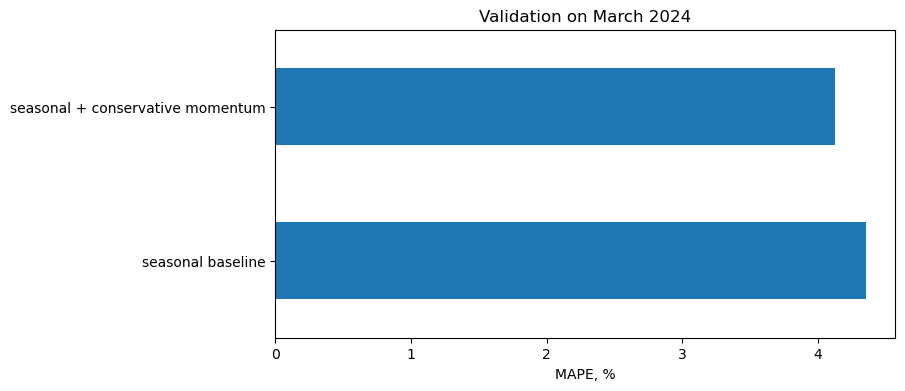

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
validation.sort_values("MAPE", ascending=False).plot.barh(
    x="method", y="MAPE", ax=ax, legend=False
)
ax.set_title("Validation on March 2024")
ax.set_xlabel("MAPE, %")
ax.set_ylabel("")
plt.show()

## 4. Forecast March 2025

Для финального прогноза используем оба известных исторических мартовских перехода:

- март 2023 / февраль 2023;
- март 2024 / февраль 2024.

In [6]:
known_mar_feb_ratios = pd.concat(
    [
        (rto["2023-03"] / rto["2023-02"]).rename("ratio"),
        (rto["2024-03"] / rto["2024-02"]).rename("ratio"),
    ]
).replace([np.inf, -np.inf], np.nan).dropna()

final_factor = known_mar_feb_ratios.median()

dec_2024 = rto["2024-12"]
jan_2025 = rto["2025-01"]
feb_2025 = rto["2025-02"]

pred_v1_2025 = feb_2025 * final_factor
rolling_3_2025 = (dec_2024 + jan_2025 + feb_2025) / 3
momentum_2025 = (feb_2025 / rolling_3_2025).replace([np.inf, -np.inf], np.nan).fillna(1)
momentum_2025 = momentum_2025.clip(0.95, 1.05)
pred_best_2025 = pred_v1_2025 * (momentum_2025 ** 0.25)

factor_summary = pd.DataFrame(
    {
        "metric": ["final seasonal factor", "ratio observations", "forecast stores"],
        "value": [final_factor, len(known_mar_feb_ratios), len(pred_best_2025)],
    }
)
factor_summary

,metric,value
0,final seasonal factor,1.1192
1,ratio observations,"37,314.0000"
2,forecast stores,"18,657.0000"


In [7]:
submission = pred_best_2025.reset_index()
submission.columns = ["new_id", "rto"]
submission["new_id"] = submission["new_id"].astype(int)
submission["rto"] = submission["rto"].round(2)
submission.to_csv(SUBMISSION_PATH, index=False)

submission.head()

,new_id,rto
0,0,"91,332,389.9800"
1,1,"44,116,082.0100"
2,2,"90,281,968.2000"
3,3,"66,134,000.9700"
4,4,"81,598,205.4600"


## 5. Submission checks

In [8]:
submission_checks = pd.DataFrame(
    {
        "metric": [
            "rows",
            "columns",
            "unique new_id",
            "missing values",
            "non-positive rto",
            "file size MB",
        ],
        "value": [
            len(submission),
            ", ".join(submission.columns),
            submission["new_id"].nunique(),
            int(submission.isna().sum().sum()),
            int((submission["rto"] <= 0).sum()),
            round(SUBMISSION_PATH.stat().st_size / 1024 / 1024, 4),
        ],
    }
)
submission_checks

,metric,value
0,rows,18657
1,columns,"new_id, rto"
2,unique new_id,18657
3,missing values,0
4,non-positive rto,0
5,file size MB,0.3161
